### Target analysis

Notebook to evaluate plausible targets for the evaluation for both claim 1 and claim 2.

In [21]:
from pathlib import Path
parent_folder = Path.cwd().resolve().parent
print(parent_folder)
data_folder = parent_folder / "data"

/Users/odei0/Uni/UZH/RL/DecisionTransformerReproducibility_Group15/gym


In [22]:
import pickle
import numpy as np
import pandas as pd

returns_data = []
for file in data_folder.glob("*.pkl"):
    print(file)
    with open(file, "rb") as f:
        paths = pickle.load(f)

    dataset_env = file.stem

    for p in paths:
        returns_data.append({
            'dataset_env': dataset_env,
            'return': np.sum(p['rewards']),
            'length': p['rewards'].shape[0]  # Number of timesteps/actions
        })


df = pd.DataFrame(returns_data)


/Users/odei0/Uni/UZH/RL/DecisionTransformerReproducibility_Group15/gym/data/ant-expert-v2.pkl
/Users/odei0/Uni/UZH/RL/DecisionTransformerReproducibility_Group15/gym/data/hopper-expert-v2.pkl
/Users/odei0/Uni/UZH/RL/DecisionTransformerReproducibility_Group15/gym/data/hopper-medium-replay-v2.pkl
/Users/odei0/Uni/UZH/RL/DecisionTransformerReproducibility_Group15/gym/data/halfcheetah-medium-replay-v2.pkl
/Users/odei0/Uni/UZH/RL/DecisionTransformerReproducibility_Group15/gym/data/ant-medium-replay-v2.pkl
/Users/odei0/Uni/UZH/RL/DecisionTransformerReproducibility_Group15/gym/data/halfcheetah-expert-v2.pkl


In [23]:
!pip install matplotlib seaborn


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip



FILE-BY-FILE SUMMARY TABLE: RETURNS & TRAJECTORY LENGTHS
                              Episodes  Total_Actions  Mean_Len  Min_Len  Max_Len      Mean_Ret      Std_Ret    Median_Ret      Min_Ret       Max_Ret       Q10_Ret       Q25_Ret       Q75_Ret       Q90_Ret
dataset_env                                                                                                                                                                                                  
ant-expert-v2                     1034         999877    967.00       21     1000   4620.729980  1409.739990   5120.149902 -1708.239990   5670.890137   2724.120117   4938.959961   5252.470215   5358.229980
ant-medium-replay-v2               485         302000    622.68        2     1000    976.049988  1006.750000    741.289978  -698.469971   3734.879883    -24.209999    198.320007   1309.060059   2701.639893
halfcheetah-expert-v2             1000        1000000   1000.00     1000     1000  10656.429688   441.899994  10703.57

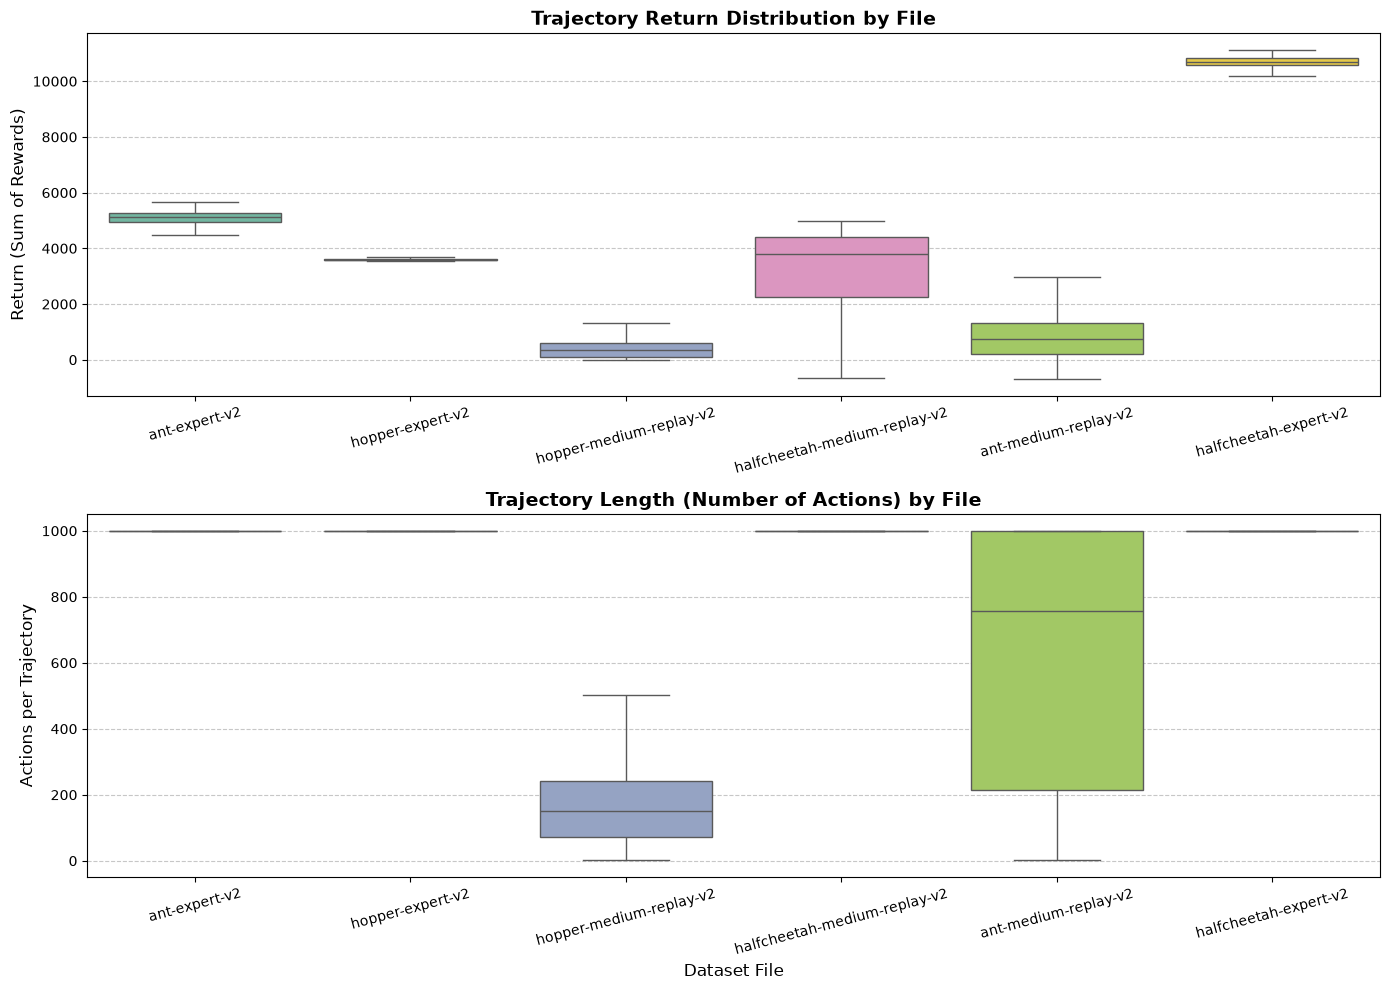

In [24]:
from matplotlib import pyplot as plt
import seaborn as sns
summary_stats = df.groupby('dataset_env').agg(
    Episodes=('return', 'count'),
    Total_Actions=('length', 'sum'),
    Mean_Len=('length', 'mean'),
    Min_Len=('length', 'min'),
    Max_Len=('length', 'max'),
    Mean_Ret=('return', 'mean'),
    Std_Ret=('return', 'std'),
    Median_Ret=('return', 'median'),
    Min_Ret=('return', 'min'),
    Max_Ret=('return', 'max'),
    Q10_Ret=('return', lambda x: x.quantile(0.10)),
    Q25_Ret=('return', lambda x: x.quantile(0.25)),
    Q75_Ret=('return', lambda x: x.quantile(0.75)),
    Q90_Ret=('return', lambda x: x.quantile(0.90)),
).round(2)

print("\n" + "="*100)
print("FILE-BY-FILE SUMMARY TABLE: RETURNS & TRAJECTORY LENGTHS")
print("="*100)
print(summary_stats.to_string())

# 3. Dual Visualizations per Dataset File
fig, axes = plt.subplots(2, 1, figsize=(14, 10))

# Plot 1: Trajectory Returns
# Replace your current sns.boxplot calls with:
sns.boxplot(
    data=df, 
    x='dataset_env', 
    y='return', 
    hue='dataset_env',  # Assign hue explicitly
    legend=False,       # Suppress redundant legend
    palette='Set2',
    showfliers=False,
    ax=axes[0]
)

axes[0].set_title('Trajectory Return Distribution by File', fontsize=14, fontweight='bold')
axes[0].set_xlabel('', fontsize=12)
axes[0].set_ylabel('Return (Sum of Rewards)', fontsize=12)
axes[0].tick_params(axis='x', rotation=15)
axes[0].grid(axis='y', linestyle='--', alpha=0.7)

# Plot 2: Trajectory Lengths (Action Count)
sns.boxplot(
    data=df, 
    x='dataset_env', 
    y='length', 
    hue='dataset_env',  # Assign hue explicitly
    legend=False,       # Suppress redundant legend
    palette='Set2',
    showfliers=False,
    ax=axes[1]
)
axes[1].set_title('Trajectory Length (Number of Actions) by File', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Dataset File', fontsize=12)
axes[1].set_ylabel('Actions per Trajectory', fontsize=12)
axes[1].tick_params(axis='x', rotation=15)
axes[1].grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
output_filename = 'd4rl_per_file_analysis.png'
plt.savefig(output_filename, dpi=300, bbox_inches='tight')
print(f"\nAnalysis complete! Saved plots to '{output_filename}'.")
plt.show()